In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## stacked-bar-chart

**Figure 3: Distribution of failures in MAST-Data across the 14 MAST failure modes, for the first 30 traces of each of 7 multi-agent systems (210 traces).** Each panel is one failure category, titled with its share of all 601 annotated failures, and each bar is stacked by that category's failure modes; as tasks and benchmarks differ across systems, the bars show system-specific failure profiles rather than a performance comparison. Failures spread across all three categories, led by system design issues at 41.8%, and the systems with explicit verifiers, ChatDev and MetaGPT, have the fewest failures in total (41 and 55).

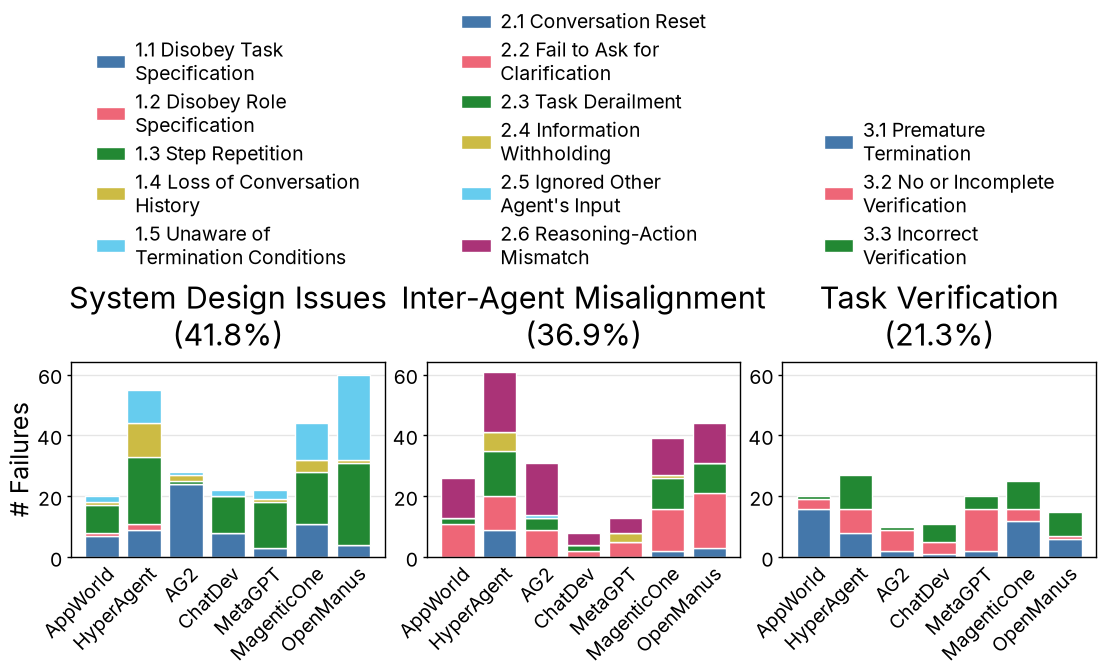

In [2]:
import textwrap

with open("../data/stacked-bar-chart.json") as f:
    data = json.load(f)

systems = data["systems"]
x = np.arange(len(systems))
mode_colors = [colors[f"series-{i}"] for i in range(1, 7)]

# started near its final height: from a much taller start, fit_height's first step collapses the layout
fig, axes = plt.subplots(1, 3, figsize=(5.5, 3.5), sharey=True)
for ax, (category_id, category) in zip(axes, data["failure_categories"].items()):
    below = np.zeros(len(systems))
    for color, (mode_id, mode_name) in zip(mode_colors, category["modes"].items()):
        counts = np.array([data["failure_counts"][system][mode_id] for system in systems])
        ax.bar(x, counts, bottom=below, color=color, edgecolor="white", linewidth=0.5,
               label=textwrap.fill(f"{mode_id} {mode_name}", 24))
        below += counts
    ax.set_title(data["panel_titles_as_printed"][category_id].replace(" (", "\n("))
    ax.set_xticks(x, labels=systems, rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.tick_params(labelleft=True)
    ax.grid(axis="x", visible=False)
    # borderaxespad clears the two-line panel title
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=4.5, frameon=False)
axes[0].set_ylabel("# Failures")

fit_height(fig, axes, aspect=0.618)
fig.savefig("../outputs/stacked-bar-chart.pdf")
fig.savefig("../outputs/stacked-bar-chart.png")
plt.show()